# Online Shoppers Purchasing Intention — Machine Learning Assignment 2

**Name/Roll No.:** 2026AJ05820

Goal: predict whether an e-commerce browsing session ends in a purchase (`Revenue`), compare five classifiers
(Logistic Regression, Decision Tree, KNN, Naive Bayes, SVM) on Accuracy, AUC, Precision, Recall, F1 and MCC,
and save them for the Streamlit app.

All reusable code lives in the `shopper_intent/` package, so this notebook, `python -m shopper_intent.train`
and `app.py` all use exactly the same cleaning, features and models.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

from shopper_intent import config as cfg
from shopper_intent.data import load_raw, clean, drop_duplicates, split, features_target

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#a3a29c"
MODEL_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
print("seed:", cfg.RNG)

seed: 42


## 1. Dataset

[UCI Online Shoppers Purchasing Intention](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)
— 12,330 sessions, 17 features + binary target. Each session belongs to a different user over a one-year period.
The csv is committed in `data/` so the notebook runs offline (BITS lab).

In [2]:
raw = load_raw()
print(f"{raw.shape[0]} rows x {raw.shape[1]} columns")
raw.head()

12330 rows x 18 columns


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### Q1 — size, missing values and feature types

In [3]:
raw.info()
# 10 numeric, 7 categorical-ish (Month, VisitorType, Weekend, + 4 integer codes), bool target

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [4]:
print("missing values:", raw.isna().sum().sum())
print("duplicate rows:", raw.duplicated().sum())
print("\nMonth values:", sorted(raw["Month"].unique()))
# no NaNs. 125 exact duplicates. "June" is spelled out while every other month is 3 letters,
# and Jan / Apr are missing entirely from the data.

missing values: 0
duplicate rows: 125

Month values: ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']


In [5]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


### Cleaning
`clean()` normalises `June -> Jun` and maps `Weekend` / `Revenue` (TRUE/FALSE) to 1/0.
Duplicates are dropped **before** splitting so the same session can't land in both train and test.

In [6]:
df = drop_duplicates(clean(raw))
print("after cleaning:", df.shape)
df[cfg.TARGET].value_counts(normalize=True).rename("share")

after cleaning: (12205, 18)


Revenue
0    0.843671
1    0.156329
Name: share, dtype: float64

**The target is imbalanced: ~84.5% no purchase vs ~15.5% purchase.** A model that always says "no purchase"
already gets 84.5% accuracy, so accuracy alone is misleading here. I'll rank models by **MCC**, which uses all four
cells of the confusion matrix, and keep F1/recall for the positive class in view.

## 2. Train / test split
Stratified 80/20 so both halves keep the same purchase rate. Everything below (EDA, tuning) uses only the
training split; the test split is written to `test_data.csv` for the Streamlit app.

In [7]:
train_df, test_df = split(df)
print(f"train {train_df.shape}  test {test_df.shape}")
print(f"purchase rate  train={train_df[cfg.TARGET].mean():.3f}  test={test_df[cfg.TARGET].mean():.3f}")

train (9764, 18)  test (2441, 18)
purchase rate  train=0.156  test=0.156


## 3. EDA (training split only)
### Univariate — counts and durations are heavily right-skewed

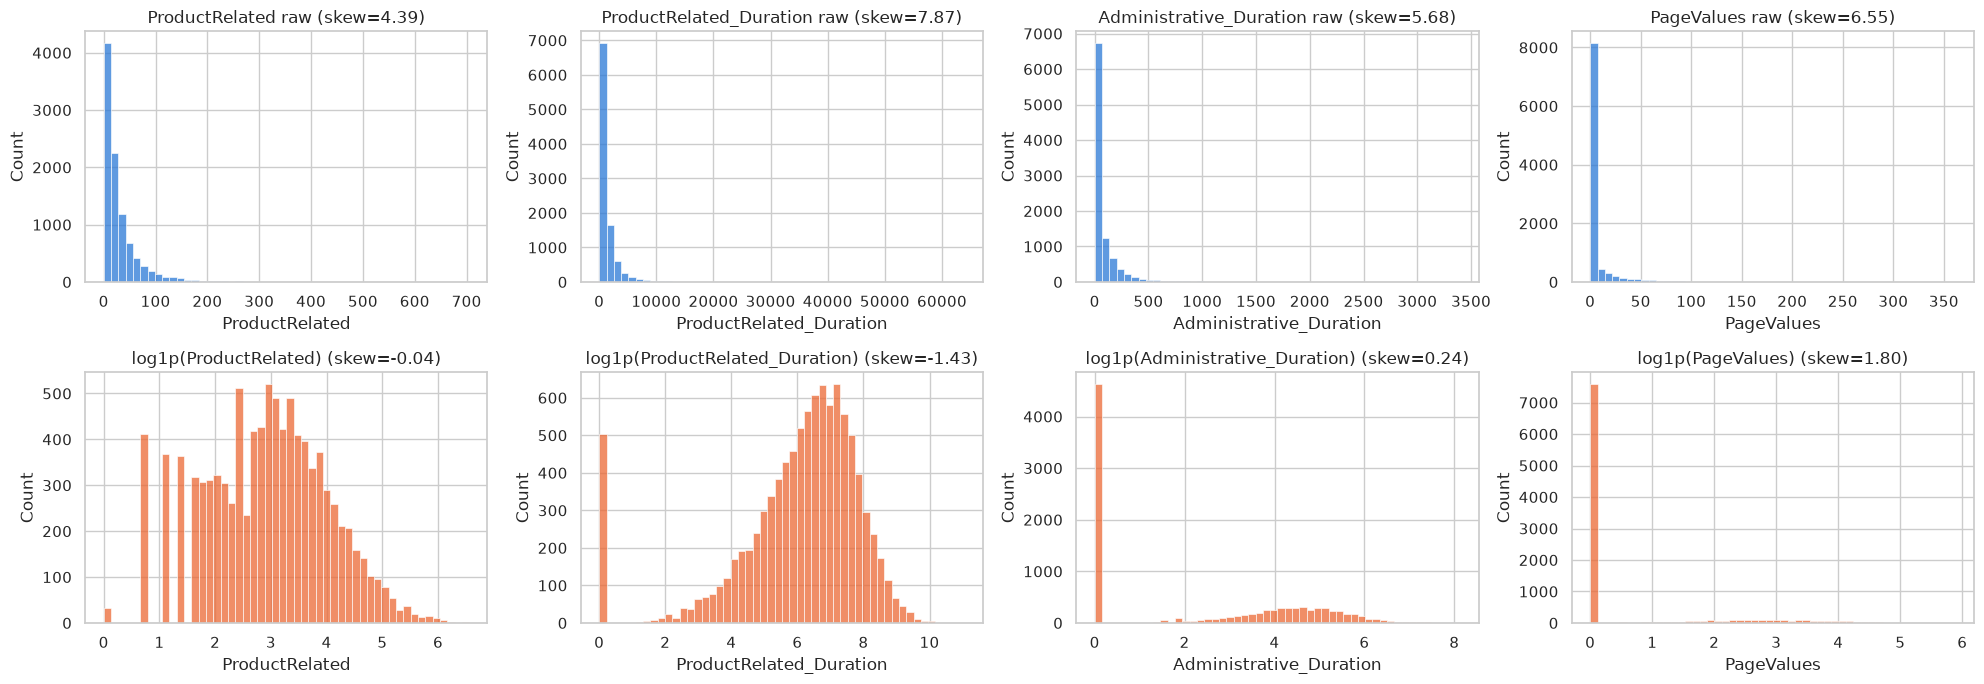

In [8]:
skewed = ["ProductRelated", "ProductRelated_Duration", "Administrative_Duration", "PageValues"]
fig, axes = plt.subplots(2, 4, figsize=(20, 7))
for i, c in enumerate(skewed):
    s = train_df[c]
    sns.histplot(s, bins=50, ax=axes[0, i], color=BLUE)
    axes[0, i].set_title(f"{c} raw (skew={skew(s):.2f})")
    sns.histplot(np.log1p(s), bins=50, ax=axes[1, i], color=ORANGE)
    axes[1, i].set_title(f"log1p({c}) (skew={skew(np.log1p(s)):.2f})")
plt.tight_layout(); plt.show()

All page counts / durations and `PageValues` have skew between 4 and 8, with a long tail of a few very long sessions.
`log1p` brings most of them close to symmetric (e.g. `ProductRelated` 4.4 → 0.0, `Administrative_Duration` 5.7 → 0.2),
so reducing skew before scaling should help. Section 5 compares the options. This matters most for KNN and SVM (distance based)
and for Logistic Regression — otherwise a single 60,000-second session dominates.

`PageValues` stays skewed after the log because ~78% of sessions are exactly 0 — that zero/non-zero split is itself
a signal (next section).

### Feature vs target

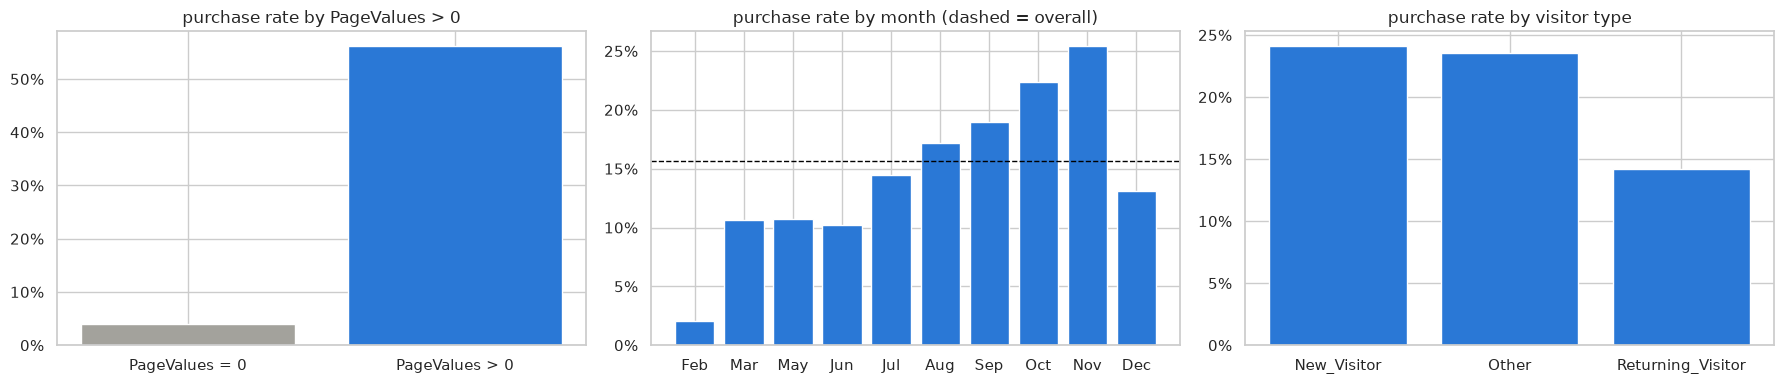

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
rate = train_df.groupby(train_df["PageValues"] > 0)[cfg.TARGET].mean()
axes[0].bar(["PageValues = 0", "PageValues > 0"], rate.values, color=[GREY, BLUE])
axes[0].set_title("purchase rate by PageValues > 0")

months = [m for m in cfg.MONTH_ORDER if m in train_df["Month"].unique()]
rate = train_df.groupby("Month")[cfg.TARGET].mean().reindex(months)
axes[1].bar(rate.index, rate.values, color=BLUE)
axes[1].axhline(train_df[cfg.TARGET].mean(), ls="--", color="black", lw=1)
axes[1].set_title("purchase rate by month (dashed = overall)")

rate = train_df.groupby("VisitorType")[cfg.TARGET].mean()
axes[2].bar(rate.index, rate.values, color=BLUE)
axes[2].set_title("purchase rate by visitor type")
for ax in axes: ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout(); plt.show()

* **PageValues** is by far the strongest signal: sessions that never reach a page with value convert ~4% of the
  time, those that do convert ~56%. The pipeline adds an explicit `HasPageValue` flag for this.
* **Month**: November (~25%) and October/September are well above average — the run-up to holiday shopping;
  February is almost dead (~2%). Month is one-hot encoded.
* **VisitorType**: new visitors convert more often (~24%) than returning ones (~14%) — returning visitors include a
  lot of people just checking something.
* `Weekend` barely moves the rate (15% vs 17.5%).

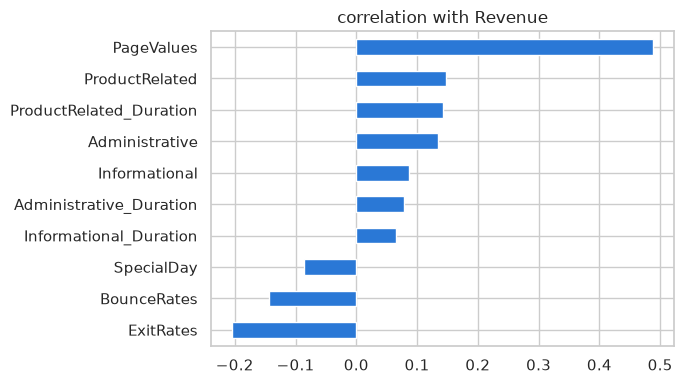

In [10]:
num = cfg.COUNT_COLS + cfg.DURATION_COLS + cfg.RATE_COLS + cfg.VALUE_COLS + [cfg.SPECIAL_DAY_COL]
train_df[num].corrwith(train_df[cfg.TARGET]).sort_values().plot.barh(figsize=(7, 4), color=BLUE)
plt.title("correlation with Revenue"); plt.tight_layout(); plt.show()

`PageValues` (0.49) dominates; `ExitRates` and `BounceRates` are negatively related (people who leave quickly
don't buy). The engagement counters are weakly positive.

### Between-feature correlation

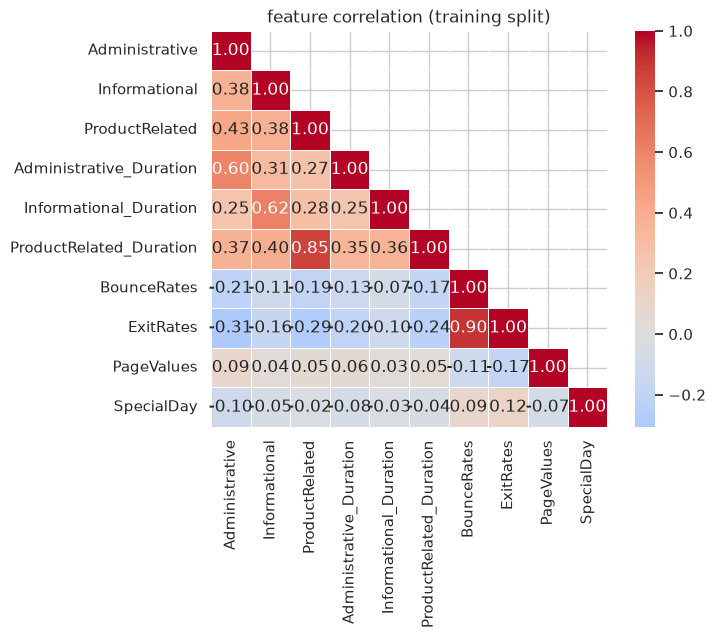

In [11]:
corr = train_df[num].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=.5)
plt.title("feature correlation (training split)"); plt.tight_layout(); plt.show()

`BounceRates` ↔ `ExitRates` = 0.90 and `ProductRelated` ↔ `ProductRelated_Duration` = 0.85.
Unlike `temp`/`atemp` in assignment 1 these are not the same measurement, and the regularised / tree models handle
the redundancy, so I keep both. It is worth remembering for **Naive Bayes**, whose independence assumption is
clearly violated by these pairs.

### Categorical codes with rare levels

In [12]:
for c in cfg.CODED_CATEGORICAL_COLS:
    vc = train_df[c].value_counts()
    print(f"{c:<17} {vc.size:>2} levels, {(vc < 30).sum()} seen < 30 times: {vc[vc < 30].to_dict()}")

OperatingSystems   8 levels, 3 seen < 30 times: {6: 12, 7: 6, 5: 5}
Browser           13 levels, 3 seen < 30 times: {12: 8, 11: 5, 9: 1}
Region             9 levels, 0 seen < 30 times: {}
TrafficType       19 levels, 5 seen < 30 times: {19: 14, 14: 11, 18: 9, 16: 2, 17: 1}


`OperatingSystems`, `Browser`, `Region`, `TrafficType` are integer **codes**, not quantities — browser 4 is not
"twice" browser 2 — so they are one-hot encoded. Levels seen fewer than 30 times are pooled into one
"infrequent" column (`min_frequency=30`), and unseen codes in an uploaded file map to that same column instead of
crashing the app.

## 4. Preprocessing pipeline
`shopper_intent/features.py` — the whole thing is the first step of each model's `Pipeline`, so the saved
`.joblib` takes raw csv rows.

| step | columns | transform |
|---|---|---|
| SessionFeatureBuilder | — | adds `TotalPages`, `TotalDuration`, `AvgSecondsPerPage`, `HasPageValue` |
| log_scaled | counts, durations, PageValues, engineered totals | one of four options, chosen per model (below) |
| scaled | BounceRates, ExitRates, SpecialDay | the matching scaler |
| flags | Weekend, HasPageValue | passthrough |
| one_hot | Month, VisitorType, 4 code columns | `OneHotEncoder(min_frequency=30)` |

In [13]:
from shopper_intent.features import build_preprocessor

X_train, y_train = features_target(train_df)
X_test, y_test = features_target(test_df)
prep = build_preprocessor().fit(X_train)
names = prep.get_feature_names_out()
print(f"{X_train.shape[1]} raw features -> {len(names)} model inputs")
print(list(names))

17 raw features -> 69 model inputs
['Administrative', 'Informational', 'ProductRelated', 'Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration', 'PageValues', 'TotalPages', 'TotalDuration', 'AvgSecondsPerPage', 'BounceRates', 'ExitRates', 'SpecialDay', 'Weekend', 'HasPageValue', 'Month_Aug', 'Month_Dec', 'Month_Feb', 'Month_Jul', 'Month_Jun', 'Month_Mar', 'Month_May', 'Month_Nov', 'Month_Oct', 'Month_Sep', 'VisitorType_New_Visitor', 'VisitorType_Other', 'VisitorType_Returning_Visitor', 'OperatingSystems_1', 'OperatingSystems_2', 'OperatingSystems_3', 'OperatingSystems_4', 'OperatingSystems_8', 'OperatingSystems_infrequent_sklearn', 'Browser_1', 'Browser_10', 'Browser_13', 'Browser_2', 'Browser_3', 'Browser_4', 'Browser_5', 'Browser_6', 'Browser_7', 'Browser_8', 'Browser_infrequent_sklearn', 'Region_1', 'Region_2', 'Region_3', 'Region_4', 'Region_5', 'Region_6', 'Region_7', 'Region_8', 'Region_9', 'TrafficType_1', 'TrafficType_10', 'TrafficType_11', 'TrafficType_

## 5. Models and tuning
`shopper_intent/models.py` holds the registry. Each model is tuned with `GridSearchCV`
(5-fold stratified, **scored on MCC**) on the training split only, once per preprocessing option, then refit on the full training split.
The SVM is wrapped in `CalibratedClassifierCV` at the end so it can output probabilities (needed for AUC/threshold
plots in the app; `SVC(probability=True)` is deprecated in scikit-learn 1.9).

The cell below runs the same code as `python -m shopper_intent.train` and writes `model/*.joblib`,
`model/metrics.json`, `test_data.csv` and `data/train_data.csv`. (~6 minutes, SVM is the slow one.)

### Scaling and normalisation: does it matter?
As in assignment 1, I don't assume a transform helps; I compare. First, each scaling option with fixed reasonable settings, using 5-fold CV on the training split, including no scaling at all as a baseline.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from shopper_intent.features import SCALERS, SCALER_LABELS, build_preprocessor
from shopper_intent.models import MODELS, build_pipeline
from shopper_intent.train import MCC_SCORER

fixed = {"logistic_regression": dict(C=0.01, class_weight="balanced"), "knn": dict(n_neighbors=21), "naive_bayes": dict(var_smoothing=0.1), "svm": dict(C=1.0)}
cv = StratifiedKFold(cfg.CV_FOLDS, shuffle=True, random_state=cfg.RNG)
rows = {}
for key, params in fixed.items():
    rows[MODELS[key].name] = {SCALER_LABELS[s]: cross_val_score(build_pipeline(key, scaler=s, **params), X_train, y_train, cv=cv, scoring=MCC_SCORER, n_jobs=-1).mean() for s in SCALERS}
    unscaled = build_pipeline(key, **params)
    unscaled.set_params(prep__columns__log_scaled="passthrough", prep__columns__scaled="passthrough")
    rows[MODELS[key].name]["No scaling"] = cross_val_score(unscaled, X_train, y_train, cv=cv, scoring=MCC_SCORER, n_jobs=-1).mean()
pd.DataFrame(rows).T.round(4)

/home/omkar/Documents/BITS_ASSIGNMENTS/SEM-1/Machine-Learning/2026AJ05820_ML_Assignment2/.venv/lib64/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/omkar/Documents/BITS_ASSIGNMENTS/SEM-1/Machine-Learning/2026AJ05820_ML_Assignment2/.venv/lib64/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to

/home/omkar/Documents/BITS_ASSIGNMENTS/SEM-1/Machine-Learning/2026AJ05820_ML_Assignment2/.venv/lib64/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/home/omkar/Documents/BITS_ASSIGNMENTS/SEM-1/Machine-Learning/2026AJ05820_ML_Assignment2/.venv/lib64/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/omkar/Documents/BITS_ASSIGNMENTS/SEM-1/Machine-Learning/2026AJ05820_ML_Assignment2/.venv/lib64/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to

,log1p + StandardScaler,log1p + RobustScaler,log1p + MinMaxScaler (normalisation),Yeo-Johnson power transform,No scaling
Logistic Regression,0.6009,0.6044,0.5920,0.5938,0.5994
KNN,0.5611,0.5813,0.3793,0.5877,0.2314
Naive Bayes,0.4708,0.5237,0.5059,0.5211,0.0935
Support Vector Machine,0.5964,0.5845,0.6027,0.6139,0.0210


Without scaling, the distance-based models collapse, so scaling clearly matters for KNN and SVM. Between the scaling options the differences are much smaller. The trainer therefore treats the choice like a hyper-parameter for each model. The decision tree skips this because splits depend only on the order of values.

In [15]:
from shopper_intent import train
from shopper_intent.models import MODELS

for key, spec in MODELS.items():
    print(f"{spec.name:<24} grid: {spec.grid}")

Logistic Regression      grid: {'clf__C': [0.001, 0.003, 0.01, 0.03, 0.1, 1.0, 10.0], 'clf__class_weight': [None, 'balanced']}
Decision Tree            grid: {'clf__max_depth': [4, 6, 8, 12, None], 'clf__min_samples_leaf': [1, 5, 20], 'clf__criterion': ['gini', 'entropy'], 'clf__class_weight': [None, 'balanced']}
KNN                      grid: {'clf__n_neighbors': [5, 11, 21, 31, 51], 'clf__weights': ['uniform', 'distance'], 'clf__p': [1, 2]}
Naive Bayes              grid: {'clf__var_smoothing': [np.float64(1e-09), np.float64(1e-08), np.float64(1e-07), np.float64(1e-06), np.float64(1e-05), np.float64(0.0001), np.float64(0.001), np.float64(0.01), np.float64(0.1), np.float64(1.0), np.float64(10.0)]}
Support Vector Machine   grid: {'clf__C': [0.5, 1.0, 4.0, 8.0], 'clf__gamma': ['scale', 0.01], 'clf__class_weight': [None, 'balanced']}


In [16]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
train.main([])

raw (12330, 18) -> deduped (12205, 18)
train (9764, 18)  test (2441, 18)  purchase rate train=0.156 test=0.156


  Logistic Regression      cv_mcc=0.6071  test_mcc=0.6150  (19.8s)  log_robust  {'C': 0.003, 'class_weight': 'balanced'}


  Decision Tree            cv_mcc=0.5865  test_mcc=0.5757  (8.1s)  log_standard  {'class_weight': None, 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 20}


  KNN                      cv_mcc=0.5891  test_mcc=0.5728  (43.5s)  yeo_johnson  {'n_neighbors': 21, 'p': 2, 'weights': 'distance'}


  Naive Bayes              cv_mcc=0.5237  test_mcc=0.5348  (11.7s)  log_robust  {'var_smoothing': 0.1}


  Support Vector Machine   cv_mcc=0.6139  test_mcc=0.6129  (214.8s)  yeo_johnson  {'C': 1.0, 'class_weight': None, 'gamma': 'scale'}

Held-out test set (sorted by MCC):
                        Accuracy     AUC  Precision  Recall      F1     MCC
Model                                                                      
Logistic Regression       0.8800  0.9240     0.5854  0.7984  0.6755  0.6150
Support Vector Machine    0.9054  0.8877     0.7525  0.5890  0.6608  0.6129
Decision Tree             0.8947  0.9033     0.6959  0.5812  0.6334  0.5757
KNN                       0.8943  0.9098     0.6962  0.5759  0.6304  0.5728
Naive Bayes               0.8189  0.8903     0.4581  0.8586  0.5974  0.5348


## 6. Evaluation on the held-out test set

In [17]:
from shopper_intent import artifacts
from shopper_intent.evaluation import Metrics, leaderboard, evaluate, confusion_frame, roc_points

board = leaderboard({name: Metrics(**m) for name, m in artifacts.load_metrics().items()})
board.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.8800,0.9240,0.5854,0.7984,0.6755,0.6150
Support Vector Machine,0.9054,0.8877,0.7525,0.5890,0.6608,0.6129
Decision Tree,0.8947,0.9033,0.6959,0.5812,0.6334,0.5757
KNN,0.8943,0.9098,0.6962,0.5759,0.6304,0.5728
Naive Bayes,0.8189,0.8903,0.4581,0.8586,0.5974,0.5348


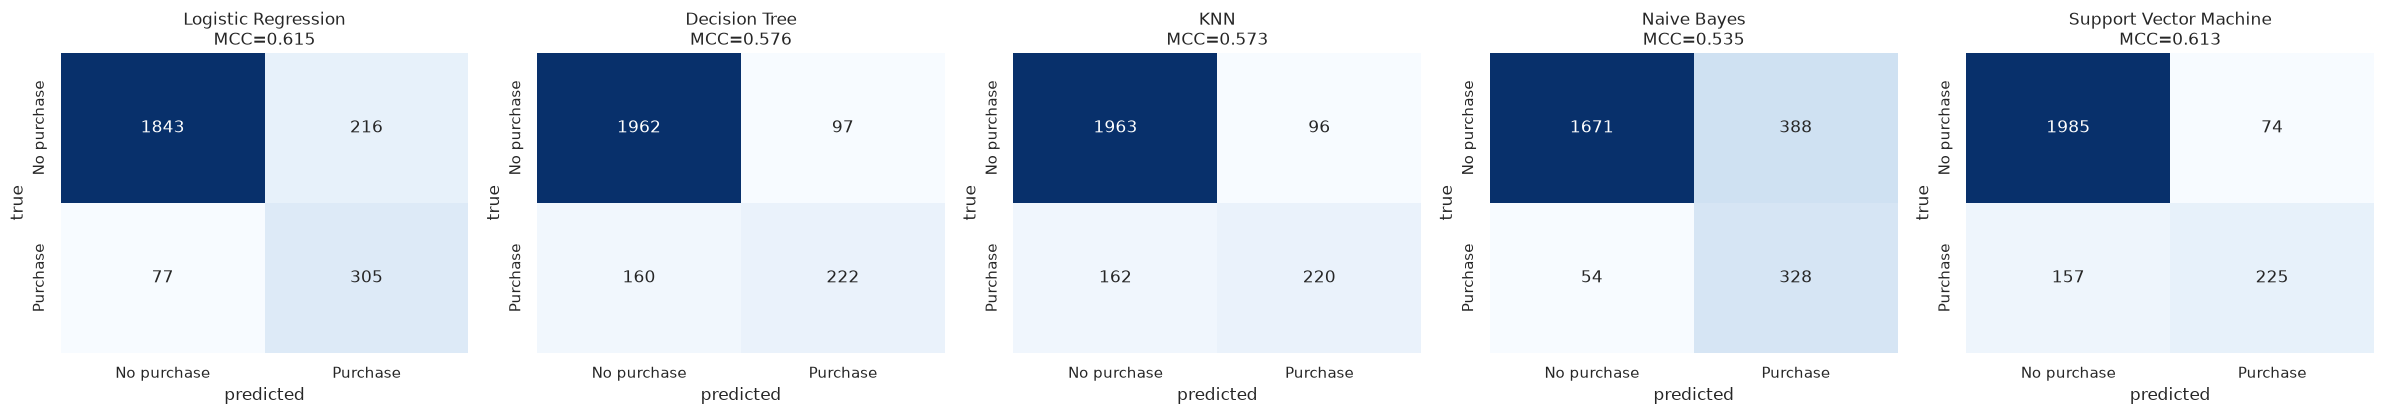

In [18]:
models = artifacts.load_all_models()
fig, axes = plt.subplots(1, 5, figsize=(24, 4.3))
for ax, (key, spec) in zip(axes, MODELS.items()):
    m, y_pred, _ = evaluate(models[key], X_test, y_test)
    cm = confusion_frame(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{spec.name}\nMCC={m.mcc:.3f}"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

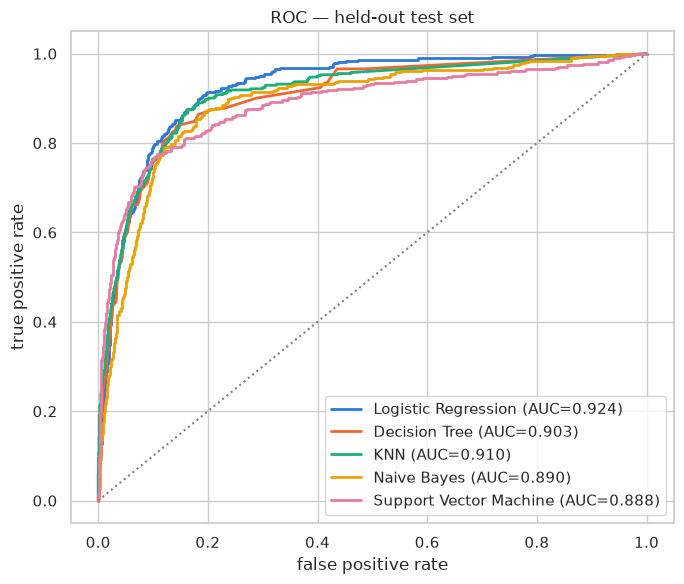

In [19]:
fig, ax = plt.subplots(figsize=(7, 6))
for color, (key, spec) in zip(MODEL_COLORS, MODELS.items()):
    m, _, scores = evaluate(models[key], X_test, y_test)
    pts = roc_points(y_test, scores)
    ax.plot(pts["fpr"], pts["tpr"], color=color, lw=2, label=f"{spec.name} (AUC={m.auc:.3f})")
ax.plot([0, 1], [0, 1], ls=":", color="grey")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.legend(loc="lower right")
ax.set_title("ROC — held-out test set"); plt.tight_layout(); plt.show()

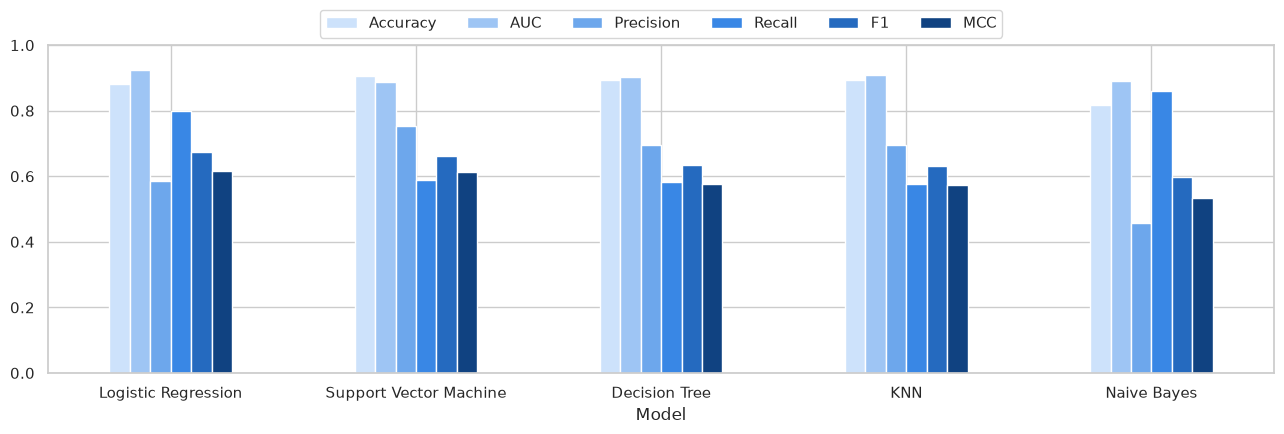

In [20]:
board[["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]].plot.bar(
    figsize=(13, 4.5), color=["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#104281"], rot=0)
plt.ylim(0, 1); plt.legend(ncol=6, loc="lower center", bbox_to_anchor=(.5, 1)); plt.tight_layout(); plt.show()

## 7. Observations

| ML Model Name | Observation about model performance |
|---|---|
| **Logistic Regression** | Best MCC (0.615), F1 (0.676) and AUC (0.924). Strong regularisation (`C=0.003`) with `class_weight="balanced"` trades precision (0.59) for high recall (0.80): it catches 305 of 382 buyers, at the cost of 216 false alarms. Once skew is reduced, the signal is close to linear (dominated by `PageValues`), so a simple model does very well. |
| **Decision Tree** | Precise (0.70) but misses ~42% of buyers (recall 0.58). The root split is `PageValues` (66% of total importance). A fully grown tree overfits badly (CV MCC 0.478 vs 0.587 for the pruned depth-8 tree). Its leaf-average probabilities are coarse, which limits AUC to 0.903. Scaling has no effect on it. |
| **KNN** | With `k=21` and distance weighting it performs close to the tree (MCC 0.573): good precision, low recall. Buyers are a minority, so they are often outvoted by non-buyer neighbours. It is very sensitive to preprocessing (CV MCC 0.466 with MinMax vs 0.589 with Yeo-Johnson), and it has the largest model file because it stores the whole training set. |
| **Naive Bayes** | Lowest accuracy (0.819) and MCC (0.535). Its independence assumption is broken (Bounce↔Exit 0.90, page counts↔durations 0.85), and the one-hot columns are not Gaussian. It has the highest recall (0.86, catching 328 of 382 buyers) but also the most false alarms (388), giving precision of 0.46. |
| **Support Vector Machine** | Highest accuracy (0.905) and precision (0.75), with the fewest false alarms (74). MCC (0.613) is nearly tied with Logistic Regression. Without class weighting it is conservative, so recall is 0.59. It has the lowest AUC (0.888), and it is by far the slowest model to train and predict. |
| **Overall, winner for this dataset?** | **Logistic Regression**, narrowly. It leads on MCC, F1 and AUC and is the fastest and smallest of the strong models. The MCC gap to the **SVM** is only 0.002, effectively a tie, and the SVM is the better choice if accuracy or precision matters most, for example when each flagged visitor gets a costly discount. The threshold slider in the app shows this trade-off live. |